In [1]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_11/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# 11.1. От ряда к обучающей выборке: DLinear

В 2022 году вышла статья [*«Are Transformers Effective for Time Series Forecasting?»*](https://arxiv.org/abs/2205.13504):
одна линейная модель на окне обошла пять трансформерных архитектур на бенчмарках долгосрочного прогноза.
Значит, прежде чем строить глубокую сеть, надо понять, что нейросеть вообще делает с рядом.

Аргумент статьи коротко:
- **Self-attention не видит порядок.** Внимание инвариантно к перестановке токенов, порядок в него добавляют
  позиционными эмбеддингами. Для текста это терпимо: смысл фразы почти не меняется при перестановке слов.
  У ряда «смысла» в отдельной точке нет — вся информация в порядке и в расстояниях между точками.
- **Нечестные бейзлайны.** Трансформеры прогнозировали весь горизонт сразу (DMS), а сравнивались
  с моделями, которые шагают по одной точке и подставляют свои прогнозы (IMS) и накапливают ошибку.
  Гипотеза авторов: выигрыш шёл от стратегии DMS, а не от внимания.
- **Проверка.** Самая простая DMS-модель — один линейный слой $\mathbb{R}^L \to \mathbb{R}^H$ (LTSF-Linear)
  и две его вариации, DLinear и NLinear. В статье на 9 датасетах они обходят FEDformer (лучший из трансформеров)
  в большинстве случаев на 20–50% по MSE (Table 2). Например, ETTm2, $H=96$: DLinear MSE 0.167, FEDformer 0.203.

Сами авторы подчёркивают: вклад статьи — не линейная модель, а вопрос «что на самом деле даёт сложная архитектура».

Разбираем:
- как ряд превращается в обучающую выборку: окно `input_size` → горизонт `h`, глобальная модель;
- базовые модели — планка, которую нейросеть обязана обойти;
- **DLinear** руками на PyTorch и тот же DLinear в `neuralforecast`;
- нормализацию окна: `scaler_type`, RevIN, NLinear.

In [2]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasetsforecast.long_horizon import LongHorizon
from neuralforecast import NeuralForecast
from neuralforecast.models import DLinear, NLinear
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive
from torch import nn
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, mse

warnings.simplefilter("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

SEED = 1
torch.manual_seed(SEED)
ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
TRAINER_KW = dict(accelerator=ACCELERATOR, enable_progress_bar=False, enable_model_summary=False, logger=False)

/Users/a.p.chikov/PycharmProjects/Временные ряды/Семинары/11/.venv/lib/python3.11/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 1] Operation not permitted.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


In [3]:
def score(cv):
    """MAE и MSE каждой модели, усреднённые по рядам и окнам кросс-валидации."""
    models = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")]
    res = evaluate(cv, metrics=[mae, mse], models=models)  # по каждому ряду и окну
    return res.groupby("metric")[models].mean().T.round(3).sort_values("mae")

## Данные: ETTm2

Температура масла (`OT`) и шесть нагрузок электрического трансформатора, шаг 15 минут, июль 2016 — февраль 2018.
Один из стандартных бенчмарков долгосрочного прогноза (на нём мерились и трансформеры, и DLinear).

`LongHorizon.load` сразу отдаёт long-формат `unique_id, ds, y` — формат statsforecast и neuralforecast.
При первом запуске скачивается архив всех бенчмарков (~300 МБ).

Мелкая деталь при чтении статьи: в Table 1 и приложении C.2 шаг ETTm1/ETTm2 указан как 5 минут, на деле он 15 минут
(96 точек в сутках) — это видно по `ds` ниже.

In [4]:
Y_df, _, _ = LongHorizon.load(directory="../data", group="ETTm2")
Y_df["ds"] = pd.to_datetime(Y_df["ds"])
print(Y_df.shape, Y_df["unique_id"].nunique(), "рядов по", Y_df.groupby("unique_id").size().iloc[0], "точек")
Y_df.head()

(403200, 3) 7 рядов по 57600 точек


,unique_id,ds,y
0,HUFL,2016-07-01 00:00:00,-0.041413
1,HUFL,2016-07-01 00:15:00,-0.185467
2,HUFL,2016-07-01 00:30:00,-0.257495
3,HUFL,2016-07-01 00:45:00,-0.577510
4,HUFL,2016-07-01 01:00:00,-0.385501


Ряды уже стандартизованы — статистиками **первых 12 месяцев** (обучающая часть стандартного протокола).
Это честно: статистики, посчитанные по всему ряду вместе с тестом, были бы утечкой из будущего.
Проверим: на первых 12 месяцах среднее 0 и std 1, на всём ряде — нет.

In [5]:
TRAIN_12M = 12 * 30 * 96  # 12 «месяцев» по 30 суток, 96 точек в сутках
pd.concat(
    {
        "первые 12 мес": Y_df.groupby("unique_id").head(TRAIN_12M).groupby("unique_id")["y"].agg(["mean", "std"]),
        "весь ряд": Y_df.groupby("unique_id")["y"].agg(["mean", "std"]),
    },
    axis=1,
).round(2).T

unique_id           HUFL  HULL  LUFL  LULL  MUFL  MULL    OT
первые 12 мес mean -0.00 -0.00 -0.00  0.00  0.00 -0.00  0.00
              std   1.00  1.00  1.00  1.00  1.00  1.00  1.00
весь ряд      mean -0.23 -0.73 -0.66  0.03 -0.11 -0.73 -0.06
              std   0.95  1.39  1.21  0.78  0.83  1.56  1.06

Среднее по всему ряду уходит от нуля — уровень рядов **дрейфует** во времени.
Посмотрим на суточные средние: после границы 12 месяцев ряды живут на другом уровне.
Этот дрейф понадобится в разделе про нормализацию.
Плоские участки весной 2017 — сбои датчиков в исходных данных: бенчмарк реальный, не вычищенный.

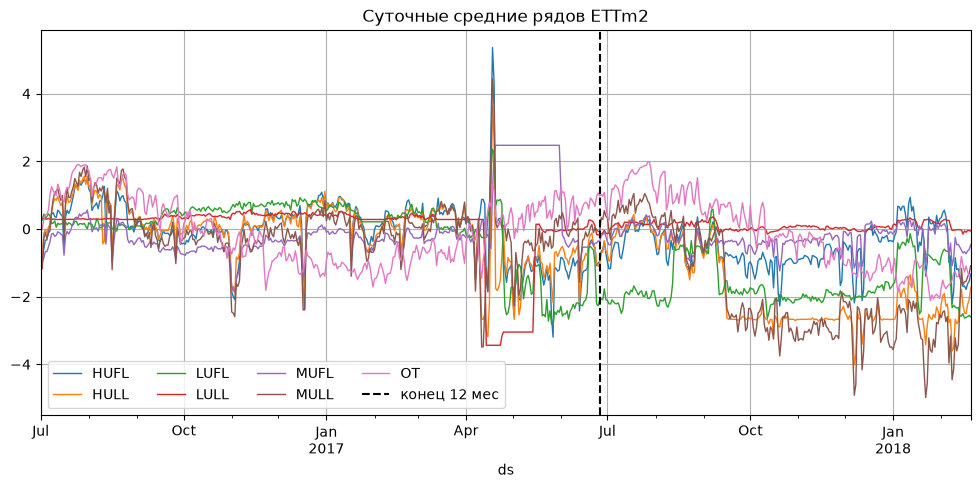

In [6]:
daily = Y_df.set_index("ds").groupby("unique_id")["y"].resample("D").mean().unstack(0)
ax = daily.plot(figsize=(12, 5), lw=1, title="Суточные средние рядов ETTm2")
ax.axvline(Y_df["ds"].iloc[TRAIN_12M], color="black", ls="--", label="конец 12 мес")
ax.legend(ncol=4);

Внутри суток — выраженный суточный цикл: период 96 точек.

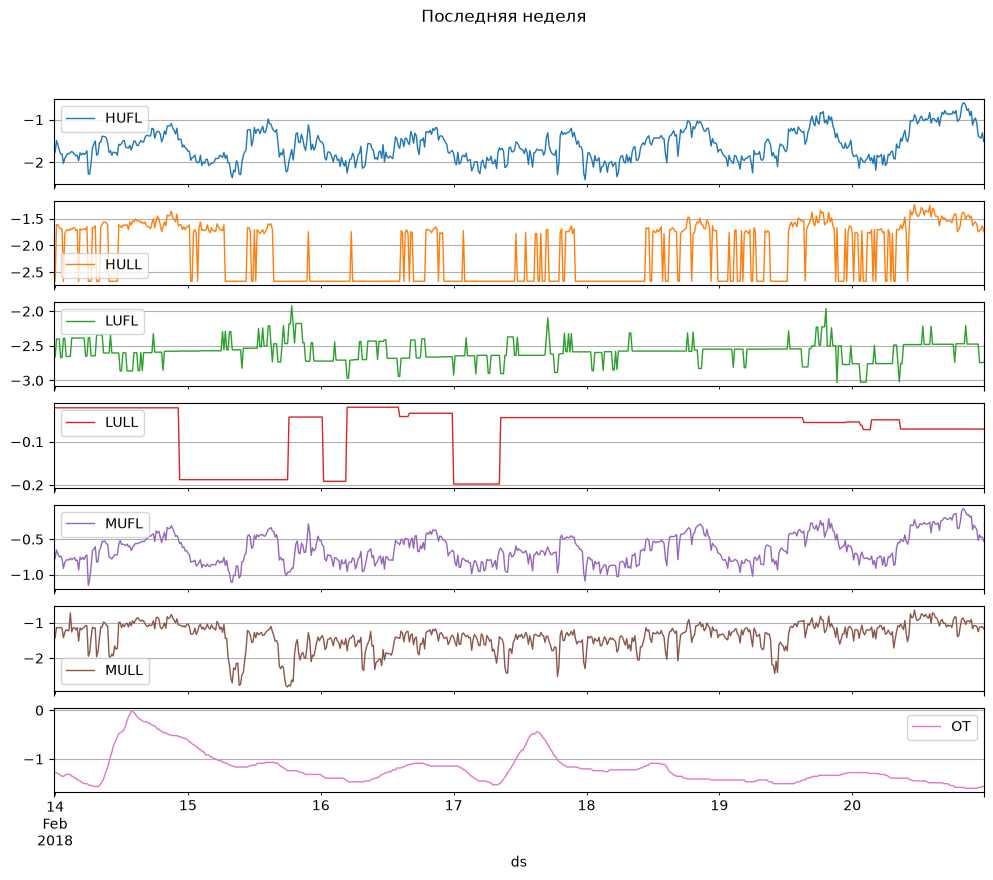

In [7]:
week = Y_df[Y_df["ds"] >= Y_df["ds"].max() - pd.Timedelta(days=7)]
week.pivot(index="ds", columns="unique_id", values="y").plot(
    subplots=True, figsize=(12, 9), lw=1, title="Последняя неделя"
);

## 1. От ряда к обучающей выборке

Прогноз сводится к обучению с учителем на парах «окно → горизонт»:
- вход — последние `input_size` = $L$ точек;
- цель — следующие `h` = $H$ точек.

Сутки — 96 точек, поэтому прогнозируем на сутки вперёд по 3.5 суткам истории (как в статье про DLinear).
В окно должно помещаться несколько сезонных периодов, иначе модель не отличит сезонный подъём от сдвига уровня.

In [8]:
H = 96  # горизонт: сутки
L = 336  # окно истории: 3.5 суток
N_WINDOWS = 5  # окон кросс-валидации в конце ряда
MAX_STEPS = 1000  # шагов градиентного спуска
LR = 1e-3

Нарежем один ряд скользящим окном с шагом 1. Ряд длины $T$ даёт $T - L - H + 1$ примеров.

In [9]:
ot = Y_df.loc[Y_df["unique_id"] == "OT", "y"].to_numpy()
windows = np.lib.stride_tricks.sliding_window_view(ot, L + H)
X_ot, Y_ot = windows[:, :L], windows[:, L:]
print("примеров:", len(windows), "= T - L - H + 1 =", len(ot) - L - H + 1)
print("X:", X_ot.shape, "Y:", Y_ot.shape)

примеров: 57169 = T - L - H + 1 = 57169
X: (57169, 336) Y: (57169, 96)


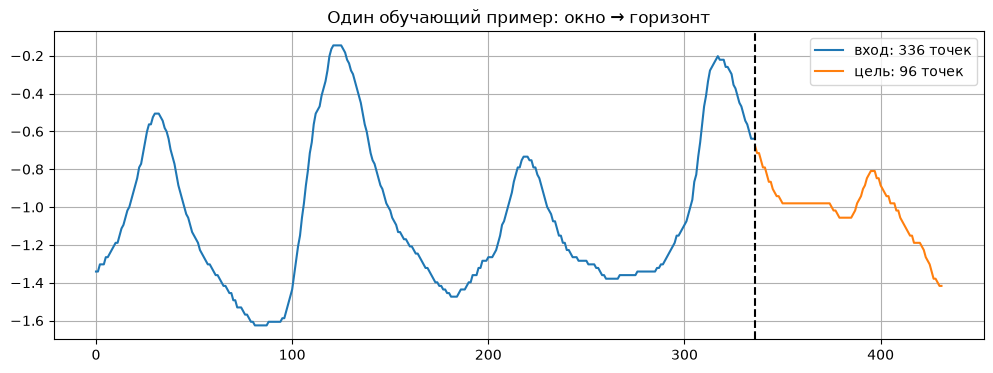

In [10]:
i = 20_000
plt.plot(np.arange(L), X_ot[i], label=f"вход: {L} точек")
plt.plot(np.arange(L, L + H), Y_ot[i], label=f"цель: {H} точек")
plt.axvline(L, color="black", ls="--")
plt.title("Один обучающий пример: окно → горизонт")
plt.legend();

Несколько важных деталей:
- **Прямой многошаговый прогноз (MIMO, в статье — DMS, direct multi-step).** Модель отображает
  $\mathbb{R}^L \to \mathbb{R}^H$ за один проход, без подстановки своих прогнозов на вход — ошибка не накапливается
  по горизонту. Альтернатива — **IMS** (iterated multi-step): выучить прогноз на один шаг и применить его $H$ раз,
  каждый раз дописывая прогноз в окно. В статье (раздел 2) компромисс сформулирован так: у IMS меньше дисперсия,
  но ошибки накапливаются; IMS лучше при очень точной одношаговой модели и малом $H$, DMS — когда несмещённую
  одношаговую модель получить трудно или $H$ велик.
- **Соседние окна почти одинаковые**: совпадают в $L-1$ точке. Независимых примеров гораздо меньше,
  чем строк в `X`, поэтому на каждом шаге обучения берут **случайный батч окон**, а не перебирают все.
  Бюджет обучения меряют в шагах градиента (`max_steps`), а не в эпохах.
- **Глобальная модель.** Окна всех 7 рядов идут в одну выборку, веса общие. Каждый ряд обрабатывается
  отдельно (channel independence) — модель не смешивает ряды между собой. В статье так и сделано:
  LTSF-Linear делит веса между переменными и не моделирует связи между ними — и всё равно обходит трансформеры,
  которые эти связи видят.
- **Разбиение по времени.** Обучаемся на прошлом, проверяем на будущем. Тест — последние
  `N_WINDOWS` суток: прогнозируем каждые сутки по истории до их начала (rolling origin).

## 2. Базовые модели

Планка качества: **Naive** (последнее значение на весь горизонт) и **SeasonalNaive(96)** (значения прошлых суток).
Глубокая модель имеет смысл, только если обходит их с запасом.

Naive — это бейзлайн *Repeat* из статьи. Даже он там бывает неудобен для трансформеров: на Exchange-Rate
Repeat обходит все трансформерные модели (примерно на 45%, Table 2). Причина — трансформеры экстраполируют
ложный тренд, выученный на шумных скачках курса (Figure 3b). На нашем ETTm2 при $H=96$ Repeat (MSE 0.266)
лучше Informer (0.365), Pyraformer (0.435) и LogTrans (0.768); его обходят только FEDformer (0.203)
и Autoformer (0.255).

`cross_validation` прогнозирует `N_WINDOWS` окон по `H` точек в конце ряда; `cutoff` — последняя точка истории окна.

Наши метрики не сравнимы с цифрами статьи напрямую: там тест — последние 4 месяца (стандартное разбиение
ETT 12/4/4 мес) и прогноз делается от каждой точки теста, а у нас — 5 суток в самом конце.
Сравнивать имеет смысл только модели внутри этого ноутбука.

In [11]:
sf = StatsForecast(models=[Naive(), SeasonalNaive(season_length=96)], freq="15min")
cv_base = sf.cross_validation(df=Y_df, h=H, n_windows=N_WINDOWS, step_size=H)
cutoffs = cv_base["cutoff"].unique()
print("cutoffs:", [str(c) for c in cutoffs])
score(cv_base)

cutoffs: ['2018-02-15 23:45:00', '2018-02-16 23:45:00', '2018-02-17 23:45:00', '2018-02-18 23:45:00', '2018-02-19 23:45:00']


metric,mae,mse
SeasonalNaive,0.207,0.109
Naive,0.226,0.139


## 3. DLinear руками

### Идея

1. Разложить окно на **тренд** (скользящее среднее, `moving_avg_window` = 25) и **остаток** (окно минус тренд).
   Края окна дополняются крайними значениями, чтобы тренд был той же длины.
2. На каждую компоненту — свой линейный слой $\mathbb{R}^L \to \mathbb{R}^H$.
3. Прогноз = сумма двух выходов.

Ни скрытых слоёв, ни нелинейностей: $\hat{y} = W_{tr}\, y_{tr} + W_{res}\, y_{res}$.

Подробнее:
- **Откуда разложение.** Его взяли из Autoformer/FEDformer: там скользящее среднее отделяет «тренд-цикл»,
  разность — «сезонную» часть. Размер ядра 25 — тот же, что в Autoformer (приложение B.2 статьи).
- **Скользящее среднее — тоже линейная операция.** Тренд $y_{tr} = A x$, где $A$ — матрица $L \times L$
  усреднения по 25 соседям, остаток $y_{res} = (I - A)x$. Значит,
  $$\hat{y} = \big(W_{tr} A + W_{res}(I - A)\big)\, x + b = W_{\text{eff}}\, x + b,$$
  то есть DLinear по выразительности **ровно один линейный слой** $\mathbb{R}^L \to \mathbb{R}^H$.
  Разложение меняет не класс моделей, а параметризацию: оптимизатору проще отдельно подобрать гладкие веса
  для медленной части и «периодические» — для быстрой. По статье это помогает, когда в данных есть явный тренд.
- **Варианты из статьи:** *Linear* — один слой $\hat{y} = W x$, $W \in \mathbb{R}^{H \times L}$;
  *DLinear* — два слоя на тренд и остаток; *NLinear* — вычесть последнее значение окна и прибавить его к прогнозу
  (раздел 4). Параметров $HL$ у Linear/NLinear и $2HL$ у DLinear (плюс смещения).
- **Короткий путь сигнала.** Любая точка окна влияет на любой шаг прогноза через один вес — в статье это
  называют $O(1)$ maximum signal traversing path length (приложение D.2).

In [12]:
class DLinearScratch(nn.Module):
    def __init__(self, input_size, h, kernel_size=25):
        super().__init__()
        self.pad = (kernel_size - 1) // 2
        self.moving_avg = nn.AvgPool1d(kernel_size, stride=1)
        self.trend_head = nn.Linear(input_size, h)
        self.resid_head = nn.Linear(input_size, h)

    def decompose(self, x):  # x: (batch, L)
        padded = torch.cat([x[:, :1].repeat(1, self.pad), x, x[:, -1:].repeat(1, self.pad)], dim=1)
        trend = self.moving_avg(padded.unsqueeze(1)).squeeze(1)
        return trend, x - trend

    def forward(self, x):
        trend, resid = self.decompose(x)
        return self.trend_head(trend) + self.resid_head(resid)

Разложение одного окна: тренд гладкий, суточный цикл ушёл в остаток.

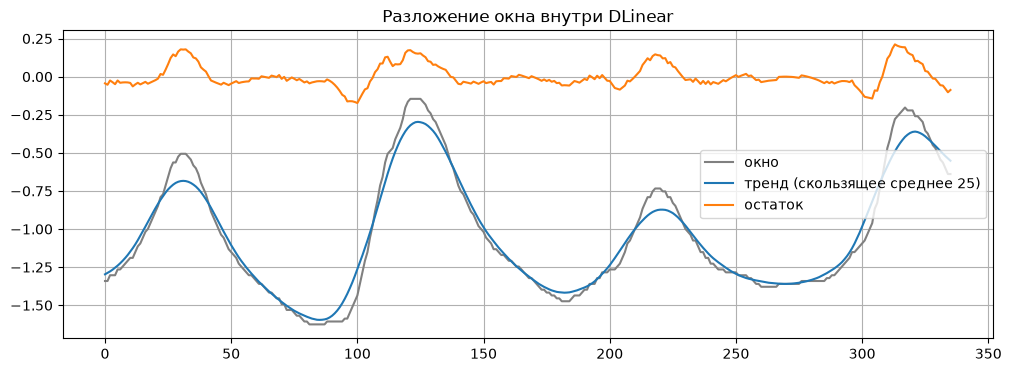

In [13]:
x = torch.tensor(X_ot[i : i + 1], dtype=torch.float32)
trend, resid = DLinearScratch(L, H).decompose(x)
plt.plot(x[0], label="окно", color="grey")
plt.plot(trend[0], label="тренд (скользящее среднее 25)")
plt.plot(resid[0], label="остаток")
plt.title("Разложение окна внутри DLinear")
plt.legend();

### Обучение

Обучающая часть — всё до первого `cutoff`. На каждом шаге берём случайный батч окон из случайных рядов
(так же делает `neuralforecast`), функция потерь — MAE.

In [14]:
wide = Y_df.pivot(index="ds", columns="unique_id", values="y")
train_arr = wide.loc[: cutoffs[0]].to_numpy().T  # (7 рядов, T_train)
print("обучающая часть:", train_arr.shape)


def sample_windows(series, batch_size, rng):
    """Случайные окна длины L + H из случайных рядов."""
    s = rng.integers(0, series.shape[0], batch_size)
    t = rng.integers(0, series.shape[1] - L - H + 1, batch_size)
    w = series[s[:, None], t[:, None] + np.arange(L + H)]
    w = torch.tensor(w, dtype=torch.float32)
    return w[:, :L], w[:, L:]

обучающая часть: (7, 57120)


1000 шагов за 2.8 с


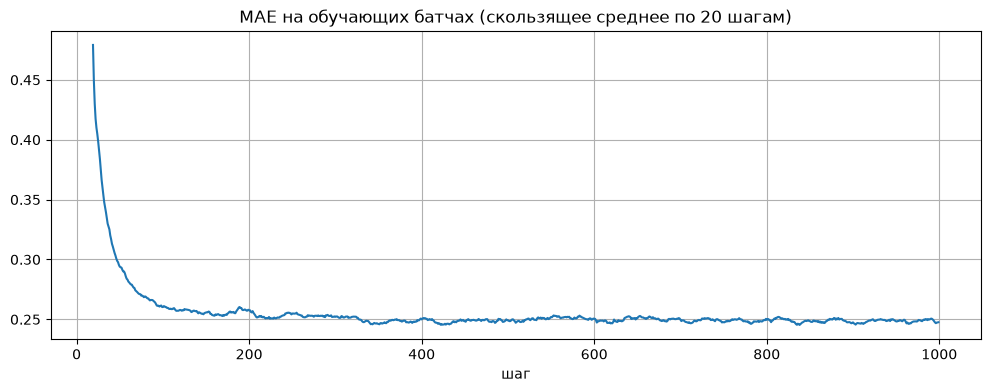

In [15]:
model = DLinearScratch(L, H)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
loss_fn = nn.L1Loss()
rng = np.random.default_rng(SEED)

start = time.time()
losses = []
for step in range(MAX_STEPS):
    xb, yb = sample_windows(train_arr, batch_size=1024, rng=rng)
    loss = loss_fn(model(xb), yb)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
print(f"{MAX_STEPS} шагов за {time.time() - start:.1f} с")

plt.plot(pd.Series(losses).rolling(20).mean())
plt.title("MAE на обучающих батчах (скользящее среднее по 20 шагам)")
plt.xlabel("шаг");

### Прогноз на окнах кросс-валидации

Для каждого `cutoff` берём последние `L` точек истории всех рядов и прогнозируем `H` точек.

In [16]:
def predict_scratch(model, cutoffs, name, permute=None):
    frames = []
    for cutoff in cutoffs:
        ctx = wide.loc[:cutoff].tail(L)  # (L, 7)
        x = torch.tensor(ctx.to_numpy().T, dtype=torch.float32)
        if permute is not None:
            x = x[:, permute]
        with torch.no_grad():
            y_hat = model(x).numpy().T  # (H, 7)
        ds = pd.date_range(cutoff, periods=H + 1, freq="15min")[1:]
        frame = pd.DataFrame(y_hat, index=pd.Index(ds, name="ds"), columns=ctx.columns)
        frames.append(frame.reset_index().melt(id_vars="ds", value_name=name).assign(cutoff=cutoff))
    return pd.concat(frames)


cv_all = cv_base.merge(predict_scratch(model, cutoffs, "DLinear (руками)"), on=["unique_id", "ds", "cutoff"])
score(cv_all)

metric,mae,mse
DLinear (руками),0.181,0.064
SeasonalNaive,0.207,0.109
Naive,0.226,0.139


### Что выучила модель

Веса слоя остатка — матрица $H \times L$: строка $h$ показывает, с каким весом каждая точка окна входит в
прогноз на шаг $h$. Диагональные полосы — модель опирается на точки **ровно сутки, двое, трое суток назад**
от прогнозируемого момента. Период 96 модель нашла сама, его никто не задавал.

Это главное практическое преимущество линейной модели — её можно прочитать. В статье (приложение D.3, Figure 7)
такие же карты весов построены для всех датасетов:
- на Traffic видны и суточная, и **недельная** периодичность: последняя точка окна получает большой вес в прогнозе
  на шаги 0, 23, 47, …, 719 (через сутки), а самый большой — на шаги 0, 167, 335, 503, 671 (через неделю);
- на Exchange-Rate периодичности нет, и веса тренда просто растут к концу окна — модель опирается на последние точки;
- чтобы карты были гладкими, авторы инициализировали веса константой $1/L$ (прогноз стартует со среднего окна),
  а не случайно. У нас инициализация случайная, поэтому картинка шумнее.

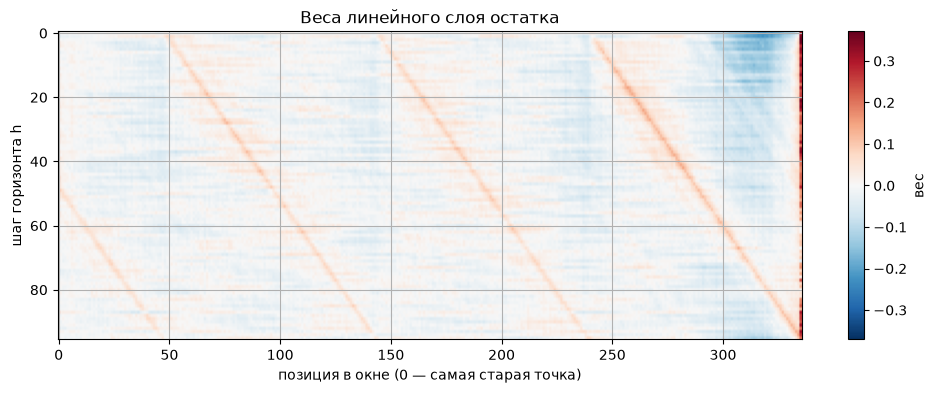

In [17]:
W = model.resid_head.weight.detach().numpy()
lim = np.abs(W).max()
plt.figure(figsize=(12, 4))
plt.imshow(W, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
plt.colorbar(label="вес")
plt.xlabel("позиция в окне (0 — самая старая точка)")
plt.ylabel("шаг горизонта h")
plt.title("Веса линейного слоя остатка");

Срез для одного шага горизонта: пики на расстоянии, кратном 96, от прогнозируемой точки.

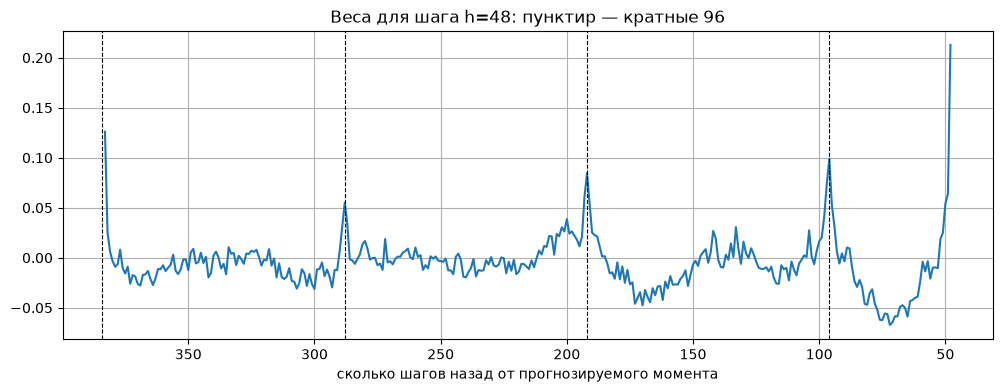

In [18]:
h = 48
lags = np.arange(L, 0, -1) + h - 1  # расстояние от точки окна до прогнозируемого момента (последняя точка — h шагов)
plt.plot(lags, W[h - 1])
for k in range(1, 5):
    plt.axvline(96 * k, color="black", ls="--", lw=0.8)
plt.gca().invert_xaxis()
plt.xlabel("сколько шагов назад от прогнозируемого момента")
plt.title(f"Веса для шага h={h}: пунктир — кратные 96");

Модель действительно использует порядок точек: если перемешать точки окна на тесте, ошибка резко вырастет.

In [19]:
perm = np.random.default_rng(0).permutation(L)
cv_perm = cv_all[["unique_id", "ds", "cutoff", "y", "DLinear (руками)"]].merge(
    predict_scratch(model, cutoffs, "DLinear (окно перемешано)", permute=perm), on=["unique_id", "ds", "cutoff"]
)
score(cv_perm)

metric,mae,mse
DLinear (руками),0.181,0.064
DLinear (окно перемешано),0.271,0.132


Это тот же тест, что в статье (Table 5), только там его применяли ко всем моделям. Результат контринтуитивный:
трансформеры перестановку почти не замечают.
- Exchange-Rate: средний рост MSE после полного перемешивания (*Shuf.*) у Linear 27.26%, у FEDformer −0.09%,
  Autoformer 0.09%, Informer −0.12%.
- ETTh1: Linear 81.06%, FEDformer 73.28%, Autoformer 56.91%, Informer 1.98%.

Модель, которой всё равно, в каком порядке идут точки, порядок не использует. Авторы делают вывод:
трансформеры с позиционными эмбеддингами сохраняют мало информации о порядке, а FEDformer и Autoformer
частично спасают встроенные «рядовые» механизмы (частотный блок, разложение, автокорреляция).

Второй вариант из Table 5 — *Half-Ex.*: поменять местами первую и вторую половины окна. У Linear на ETTh1 MSE
выросло всего на 4.78% — против 81.06% при полном перемешивании. Одно из объяснений: там окно 96 часов,
половина — 48 часов, ровно двое суток, и после обмена каждая точка остаётся в той же фазе суточного цикла.

Проверим на нашей модели, какие перестановки ей важны. Меняем местами два соседних блока окна:
- два **самых старых** дня (точки 0–95 и 96–191) — свежая история не тронута;
- два **последних** дня (блоки по 96 точек) — свежий день заменён позавчерашним, но фаза суток сохранена;
- два последних блока по **84** точки — свежие точки тоже заменены, и фаза сбита на 84 шага.

In [20]:
def swap_blocks(start, size):
    """Перестановка позиций окна: блоки [start, start+size) и [start+size, start+2*size) меняются местами."""
    p = np.arange(L)
    a, b = slice(start, start + size), slice(start + size, start + 2 * size)
    p[a], p[b] = np.arange(L)[b], np.arange(L)[a]
    return p


variants = {
    "обмен двух старых дней": swap_blocks(0, 96),
    "обмен двух последних дней (фаза та же)": swap_blocks(L - 192, 96),
    "обмен двух последних блоков по 84 (фаза сбита)": swap_blocks(L - 168, 84),
}
cv_shift = cv_perm
for name, p in variants.items():
    cv_shift = cv_shift.merge(predict_scratch(model, cutoffs, name, permute=p), on=["unique_id", "ds", "cutoff"])
score(cv_shift)

metric,mae,mse
обмен двух старых дней,0.180,0.063
DLinear (руками),0.181,0.064
обмен двух последних дней (фаза та же),0.231,0.110
обмен двух последних блоков по 84 (фаза сбита),0.249,0.124
DLinear (окно перемешано),0.271,0.132


Картина такая:
- перестановка в старой части окна почти ничего не меняет — основной вклад дают последние сутки;
- если трогать свежие точки, качество падает в любом случае, но обмен, сохраняющий фазу суток,
  обходится дешевле, чем обмен со сбитой фазой.

Модель использует порядок ровно в той мере, в какой он несёт уровень (свежие точки) и сезонность (фаза).

### DLinear — это один линейный слой

Проверим формулу $W_{\text{eff}} = W_{tr} A + W_{res}(I - A)$ из начала раздела. Матрицу усреднения $A$ получим,
прогнав через `decompose` единичную матрицу (строка $j$ — разложение импульса в позиции $j$).
Заодно посчитаем параметры.

In [21]:
with torch.no_grad():
    A = model.decompose(torch.eye(L))[0].T  # (L, L): тренд = A @ x
    W_eff = model.trend_head.weight @ A + model.resid_head.weight @ (torch.eye(L) - A)
    b_eff = model.trend_head.bias + model.resid_head.bias
    xb, _ = sample_windows(train_arr, batch_size=256, rng=np.random.default_rng(0))
    diff = (model(xb) - (xb @ W_eff.T + b_eff)).abs().max().item()
print(f"max |DLinear(x) - (W_eff x + b)| = {diff:.1e}")


def n_params(m):
    return sum(p.numel() for p in m.parameters())


print(f"параметров: L={L}, H={H}: {n_params(model):,}; L=96, H=720 (как в Table 8): {n_params(DLinearScratch(96, 720)):,}")

max |DLinear(x) - (W_eff x + b)| = 7.4e-06
параметров: L=336, H=96: 64,704; L=96, H=720 (как в Table 8): 139,680


Разница на уровне округления float32: DLinear действительно эквивалентен одному линейному слою.

Число параметров для $L=96$, $H=720$ совпадает с Table 8 статьи (139.7K). Там же для сравнения
(Electricity, $L=96$, $H=720$, среднее по 5 запускам):

| модель | параметры | время инференса | память GPU |
|---|---|---|---|
| DLinear | 139.7K | 0.4 ms | 687 MiB |
| Transformer (обычный) | 13.61M | 26.8 ms | 6091 MiB |
| Informer | 14.39M | 49.3 ms | 3869 MiB |
| Autoformer | 14.91M | 164.1 ms | 7607 MiB |
| FEDformer | 20.68M | 40.5 ms | 4143 MiB |

Ещё одно наблюдение из статьи: «эффективные» трансформеры с теоретической сложностью $O(L)$ или $O(L \log L)$
вместо $O(L^2)$ на практике в основном не быстрее обычного трансформера (Autoformer — в 6 раз медленнее);
исключение — Pyraformer (3.4 ms), но у него 241.4M параметров. А память обычного трансформера при $H=720$
вполне помещается в GPU, так что борьба с $O(L^2)$ на этих бенчмарках решала не главную проблему.

### Прямой прогноз против итеративного

Гипотеза статьи — трансформеры выигрывали у старых бейзлайнов в основном за счёт DMS. Сравним обе стратегии
на самой простой модели — *Linear* из статьи, без разложения. Она линейна, поэтому её можно не обучать
градиентом, а решить методом наименьших квадратов (с маленькой ridge-регуляризацией) за доли секунды:
- **DMS**: одна регрессия окна на все $H$ следующих точек;
- **IMS**: регрессия окна на одну следующую точку, применяется $H$ раз со своим прогнозом на входе.

MAE по всему горизонту: {'DMS': 0.179, 'IMS': 0.182}


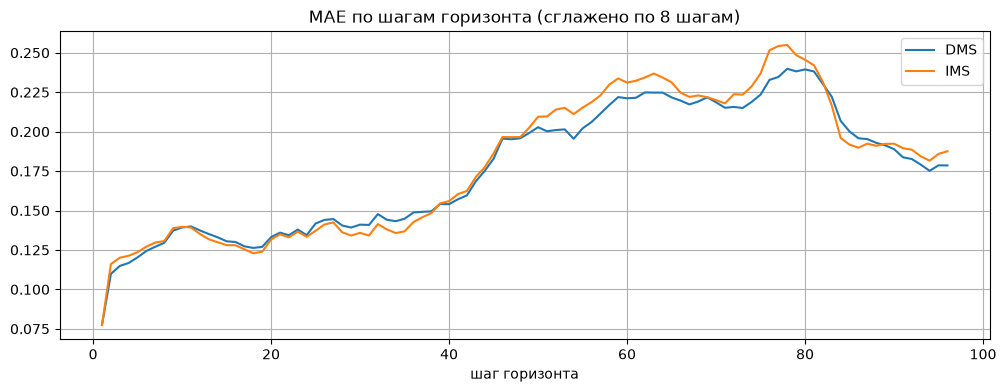

In [22]:
w = np.concatenate([np.lib.stride_tricks.sliding_window_view(s, L + H)[::4] for s in train_arr])  # каждое 4-е окно
X = np.c_[w[:, :L], np.ones(len(w))]  # + столбец для смещения
XtX = X.T @ X + 1e-3 * np.eye(L + 1)
B_dms = np.linalg.solve(XtX, X.T @ w[:, L:])  # (L+1, H)
B_ims = np.linalg.solve(XtX, X.T @ w[:, L])  # (L+1,)

abs_err = {"DMS": [], "IMS": []}
for cutoff in cutoffs:
    ctx = wide.loc[:cutoff].tail(L).to_numpy().T  # (7, L)
    fact = wide.loc[cutoff:].iloc[1 : H + 1].to_numpy().T  # (7, H)
    buf = ctx.copy()
    for _ in range(H):
        buf = np.c_[buf, np.c_[buf[:, -L:], np.ones(len(buf))] @ B_ims]
    abs_err["DMS"].append(np.abs(np.c_[ctx, np.ones(len(ctx))] @ B_dms - fact))
    abs_err["IMS"].append(np.abs(buf[:, L:] - fact))

mae_by_step = pd.DataFrame({k: np.concatenate(v).mean(axis=0) for k, v in abs_err.items()}, index=np.arange(1, H + 1))
print("MAE по всему горизонту:", mae_by_step.mean().round(3).to_dict())
mae_by_step.rolling(8, min_periods=1).mean().plot(title="MAE по шагам горизонта (сглажено по 8 шагам)")
plt.xlabel("шаг горизонта");

Что видно:
- обычный МНК без всякого разложения даёт то же качество, что и DLinear, обученный градиентом. В статье на ETTm2
  при $H=96$ это тоже так: MSE у Linear 0.168, у NLinear и DLinear по 0.167 (Table 2);
- ошибка растёт с шагом горизонта у обеих стратегий; в первой трети горизонта они неразличимы, во второй
  половине IMS почти везде немного хуже — так выглядит накопление ошибки;
- для линейной модели разница небольшая: итерированный линейный прогноз сам остаётся линейной функцией окна.
  Сильнее накопление проявляется у нелинейных моделей и на длинных горизонтах (720 и больше), где и мерились
  трансформеры.

## 4. Тот же DLinear в neuralforecast

Всё, что мы писали руками — нарезка окон, случайные батчи, цикл обучения, прогноз по `cutoff`, —
спрятано в `NeuralForecast`. Соответствие параметров:

| руками | `neuralforecast` |
|---|---|
| `L` | `input_size` |
| `H` | `h` |
| `kernel_size=25` | `moving_avg_window` |
| число шагов цикла | `max_steps` |
| окон в батче (1024) | `windows_batch_size` (рядов в батче — `batch_size`) |
| `nn.L1Loss()` | `loss=MAE()` (по умолчанию) |
| `Adam(lr=...)` | `learning_rate` |

Обучение один раз на истории до первого `cutoff`, прогноз — на тех же окнах, что у базовых моделей.

In [23]:
dlinear = DLinear(
    h=H,
    input_size=L,
    moving_avg_window=25,
    max_steps=MAX_STEPS,
    learning_rate=LR,
    random_seed=SEED,
    alias="DLinear (neuralforecast)",
    **TRAINER_KW,
)
nf = NeuralForecast(models=[dlinear], freq="15min")
start = time.time()
cv_nf = nf.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
print(f"обучение + прогноз: {time.time() - start:.1f} с")

cv_all = cv_all.merge(cv_nf.drop(columns="y"), on=["unique_id", "ds", "cutoff"])
score(cv_all)

обучение + прогноз: 7.9 с


metric,mae,mse
DLinear (neuralforecast),0.177,0.064
DLinear (руками),0.181,0.064
SeasonalNaive,0.207,0.109
Naive,0.226,0.139


Версии руками и из библиотеки дают близкое качество: это одна и та же модель.
Расхождение в третьем знаке — разная инициализация и разные случайные батчи.

Прогнозы на одном окне:

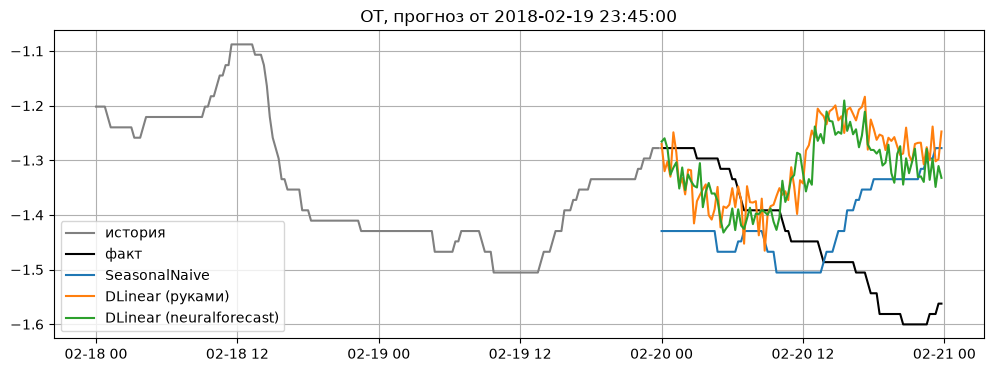

In [24]:
uid, cutoff = "OT", cutoffs[-1]
hist = Y_df[(Y_df["unique_id"] == uid) & (Y_df["ds"] <= cutoff)].tail(2 * H)
fc = cv_all[(cv_all["unique_id"] == uid) & (cv_all["cutoff"] == cutoff)]
plt.plot(hist["ds"], hist["y"], color="grey", label="история")
plt.plot(fc["ds"], fc["y"], color="black", label="факт")
for col in ["SeasonalNaive", "DLinear (руками)", "DLinear (neuralforecast)"]:
    plt.plot(fc["ds"], fc[col], label=col)
plt.title(f"{uid}, прогноз от {cutoff}")
plt.legend();

## 5. Нормализация окна

Глобальная модель — одни веса на все ряды. Две проблемы:
- ряды в **разных масштабах** (кВт и МВт): крупные ряды забирают всю функцию потерь, общие веса не подходят никому;
- **дрейф уровня** (раздел «Данные»): модель училась на одном уровне, а прогнозирует на другом.

Решение — нормировать **каждое окно** его собственными статистиками и возвращать их в прогноз:

- `scaler_type="identity"` — без нормализации (по умолчанию у DLinear);
- `scaler_type="standard"` — вычесть среднее окна, поделить на std; на выходе — обратно;
- `scaler_type="revin"` — то же + обучаемые сдвиг и масштаб (RevIN);
- **NLinear** — вычесть последнее значение окна и прибавить его к прогнозу: модель учит только отклонение
  от текущего уровня. Это нормализация, встроенная в архитектуру.

Статистики окна считаются только по прошлому, поэтому такие схемы безопасны по построению — утечки нет.

Формулы. Для окна $x_{1..L}$:
- standard: $\tilde{x} = (x - \mu_x)/\sigma_x$, прогноз $\hat{y} = \sigma_x\, f(\tilde{x}) + \mu_x$;
- RevIN: то же, но после нормировки $\tilde{x} \cdot \gamma + \beta$ с обучаемыми $\gamma, \beta$,
  на выходе — обратное преобразование (*reversible* instance normalization);
- NLinear: $\hat{y} = W (x - x_L) + x_L$.

Откуда NLinear (приложение D.1 статьи): ряды бенчмарков нормируют статистиками обучающей части, и если на тесте
уровень ушёл, среднее теста уже не 0. Модель, которая прогнозирует «в районе обучающего уровня», ошибается
на весь сдвиг. На гистограммах train/test (Figure 5) такой сдвиг явно виден у ETTh1, ETTh2 и ILI — и там NLinear
выигрывает сильнее всего: на ETTh2 при $H=720$ MSE у Linear 0.698, у NLinear 0.394 (Table 2).
На Electricity сдвига нет, и, по словам авторов, обычного Linear достаточно.

In [25]:
common = dict(h=H, input_size=L, max_steps=MAX_STEPS, learning_rate=LR, random_seed=SEED, **TRAINER_KW)
nf_norm = NeuralForecast(
    models=[
        DLinear(scaler_type="standard", alias="DLinear + standard", **common),
        DLinear(scaler_type="revin", alias="DLinear + revin", **common),
        NLinear(alias="NLinear", **common),
    ],
    freq="15min",
)
cv_norm = nf_norm.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
cv_all = cv_all.merge(cv_norm.drop(columns="y"), on=["unique_id", "ds", "cutoff"])
score(cv_all.drop(columns=["DLinear (руками)"]))

metric,mae,mse
DLinear (neuralforecast),0.177,0.064
DLinear + standard,0.177,0.065
DLinear + revin,0.177,0.065
NLinear,0.179,0.066
SeasonalNaive,0.207,0.109
Naive,0.226,0.139


На ETTm2 разницы нет. Две причины:
- ряды уже стандартизованы и лежат в одной шкале — проблемы масштаба нет;
- линейная модель сама переносит сдвиг уровня. Сдвиг окна на $c$ сдвигает тренд на $c$, остаток не меняет,
  и прогноз сдвигается на $c \cdot \sum_j W_{tr}[h, j]$. Если сумма весов тренда около 1 — модель
  эквивариантна к уровню без всякой нормализации.

Это согласуется со статьёй: на ETTm2 при $H=96$ NLinear и DLinear дают одинаковое MSE 0.167 (Table 2),
хотя дрейф уровня в ETTm2 тоже есть. Проверим сумму весов тренда на модели, обученной руками:

In [26]:
row_sums = model.trend_head.weight.detach().numpy().sum(axis=1)
print(f"сумма весов тренда по шагам горизонта: среднее {row_sums.mean():.3f}, от {row_sums.min():.3f} до {row_sums.max():.3f}")

сумма весов тренда по шагам горизонта: среднее 0.975, от 0.932 до 1.052


### Ряды в разных масштабах

Теперь сломаем данные так, как это бывает в жизни: переведём ряды в разные «единицы» — умножим на 1…1000
и сдвинем уровень. Обучаем на таких рядах, метрики считаем после обратного пересчёта, чтобы они были
сравнимы с таблицей выше.

In [27]:
scale = dict(zip(sorted(Y_df["unique_id"].unique()), [1, 3, 10, 30, 100, 300, 1000]))
factor = Y_df["unique_id"].map(scale)
Y_scaled = Y_df.assign(y=Y_df["y"] * factor + 5 * factor)
Y_scaled.groupby("unique_id")["y"].agg(["mean", "std"]).round(1).T

unique_id,HUFL,HULL,LUFL,LULL,MUFL,MULL,OT
mean,4.8,12.8,43.4,151.0,489.4,1281.1,4944.5
std,1.0,4.2,12.1,23.4,82.7,467.0,1064.2


In [28]:
nf_scaled = NeuralForecast(
    models=[DLinear(scaler_type=s, alias=f"DLinear + {s}", **common) for s in ["identity", "standard"]],
    freq="15min",
)
cv_scaled = nf_scaled.cross_validation(df=Y_scaled, n_windows=N_WINDOWS, step_size=H)
f = cv_scaled["unique_id"].map(scale)
for col in ["y", "DLinear + identity", "DLinear + standard"]:
    cv_scaled[col] = cv_scaled[col] / f - 5  # обратно в исходную шкалу
score(cv_scaled)

metric,mae,mse
DLinear + standard,0.176,0.064
DLinear + identity,0.199,0.075


Без нормализации качество заметно просело — по MAE ближе к seasonal naive, чем к DLinear на исходных данных:
крупные ряды задают функцию потерь, мелкие модель почти игнорирует. Со `standard` — то же качество, что на исходных данных: каждое окно приходит в сеть
в одной шкале.

Вывод: нормализация — не деталь препроцессинга, а часть модели. Нужна ли она и какая — зависит от данных
и архитектуры, и проверять это надо так же, как выбор модели, — на честной кросс-валидации.
Для глобальной модели на рядах разного масштаба нормализация окна обязательна.

## 6. Для самостоятельного изучения: длина окна

В статье про DLinear ошибка линейной модели падала с ростом окна до нескольких сотен точек: чем больше
суточных периодов в окне, тем точнее оценка весов. Проверьте `input_size` = 96 / 336 / 720.
На наших 5 окнах оценка шумная — увеличьте `n_windows` и посмотрите, сохранится ли порядок.

Что в статье про длину окна (Figure 4, Figure 6, Table 3):
- у LTSF-Linear ошибка с ростом $L$ падает на большинстве датасетов (сильнее всего — Traffic и ETTm1);
  исключение — Exchange-Rate, где у курса нет периодичности и длинная история не помогает;
- у трансформеров ошибка с ростом $L$ стоит на месте или растёт: длинное окно они используют, чтобы переобучиться
  на шум. Поэтому в трансформерных статьях и брали $L=96$;
- **Close vs Far** (Table 3): прогнозировать те же 720 точек по ближнему окну (точки 96…191) или по дальнему
  (0…95) трансформерам почти всё равно: MSE FEDformer на Electricity 0.251 против 0.265, на Traffic 0.631
  против 0.645. Значит, они берут из окна в основном тренд и периодичность, а их видно и в дальнем окне.

Помните: при сравнении разных моделей одинаковый `input_size` — не нейтральное условие.
Одни архитектуры извлекают пользу из длинной истории, другие нет; честно — подбирать `L` для каждой модели.
В статье так и сделано: LTSF-Linear с $L=336$, трансформеры с $L=96$ (приложение B.2).

In [29]:
nf_len = NeuralForecast(
    models=[
        DLinear(scaler_type="standard", alias=f"DLinear L={n}", **{**common, "input_size": n})
        for n in [96, 336, 720]
    ],
    freq="15min",
)
cv_len = nf_len.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
score(cv_len)

metric,mae,mse
DLinear L=336,0.177,0.065
DLinear L=96,0.183,0.071
DLinear L=720,0.187,0.071


## 7. Итоги

| Решение | Что выбрали | Почему |
|---|---|---|
| Обучающая выборка | окна `input_size` → `h`, случайные батчи | соседние окна почти одинаковые |
| Стратегия горизонта | весь горизонт одним вектором (MIMO) | ошибка не накапливается |
| Ряды | одна глобальная модель, каналы независимо | больше данных на те же веса |
| Проверка | разбиение по времени, несколько окон в конце | модель проверяется на будущем |
| Планка | Naive, SeasonalNaive | нейросеть обязана обойти их с запасом |
| Нормализация | по окну: `standard` / `revin` / NLinear | ряды в разных масштабах, дрейф уровня |

Что вынести из статьи:
- DLinear — два линейных слоя, а по сути один: $W_{\text{eff}} = W_{tr} A + W_{res}(I - A)$. Разложение — удобная
  параметризация, а не дополнительная выразительность;
- сложная архитектура должна доказать выигрыш против простого DMS-бейзлайна, а не против IMS-моделей;
- модель, которой всё равно, перемешано ли окно, не использует порядок — у трансформеров это так (Table 5);
- тест «обрезать модель до линейной» полезен: в статье (Table 4) Informer по мере упрощения до одного линейного
  слоя становится только лучше — на Exchange-Rate при $H=96$ MSE 0.847 → 0.084;
- данных для трансформеров хватало: обучение на одном году Traffic вместо полной истории даже уменьшило
  ошибку FEDformer и Autoformer в большинстве случаев (Table 7).

При правильной подготовке данных DLinear — сильный и дешёвый бейзлайн, с которого стоит начинать любое сравнение.
Его ограничения авторы называют сами: малая ёмкость и плохая реакция на смену режима (change points).
Чего ему не хватает — нелинейности и явной структуры прогноза через базисы тренда и сезонности.
Это следующий шаг — N-BEATS.